# 1D CNNs for multilabel PTB-XL classification

This notebook displays the data loading and preprocessing steps, model architecture, training and hyperparameter tuning results, and multilabel classification performance results for 1D convolutional neural networks (CNNs). The last section also has an ECG and demographic feature importance analysis using a permutation-based approach. 

I used Codex to write the Python code for fitting the CNN model. Configuration, data preparation, and completion bookkeeping are in `cnn_notebook_support.py`; reproduction and methodological details are in `CNN_README.md`. 

The main takeaways here are that the CNN performs very well for classifying samples from our ECG dataset, achieving macro-AUROC values of around 0.9 on the test set. Concatenating demographic features (age and sex) to the ECG waveform features resulted in minimal classification performance improvements. Regarding feature importance, V5 (one of the six chest leads) had the largest change in classification performance after permutation. We should investigate this finding to see if it is consistent with other ECG-related studies.

## 1. PyTorch datasets and data loaders
Waveforms remain memory-mapped on disk and are standardized on access. Each
minibatch has ECG shape **(batch, 12, 1000)**, demographics **(batch, 2)**, and
binary labels **(batch, 5)**. Only training is shuffled. The same loader inputs and
recording order are used for both models.

In [4]:
from pathlib import Path
import sys

_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
              if (p / "configs/preprocessing.yaml").is_file()), None)
if _ROOT is None:
    raise FileNotFoundError("Run from within the BIOS784 repository.")
sys.path.insert(0, str(_ROOT / "analysis/Thomas"))
from cnn_notebook_support import initialize, finalize_run

%matplotlib inline
globals().update(initialize())

display(Code(inspect.getsource(ECGDataset), language="python"))
training_loader = make_loader(ECGDataset(data, indices["train"], parameters),
                              BATCH_SIZE, shuffle=True, workers=0, seed=SEED)
x_batch, demographic_batch, target_batch = next(iter(training_loader))
print("ECG:", tuple(x_batch.shape), "demographics:", tuple(demographic_batch.shape),
      "targets:", tuple(target_batch.shape))
assert x_batch.shape[1:] == (12, 1000)
assert target_batch.shape[1] == 5
# No identifiers or large arrays are printed.

class ECGDataset(Dataset):
    """Memory-map waveforms lazily in each worker; return (12,1000), (2,), (5,)."""
    def __init__(self, data, indices, parameters, permutation=None):
        self.path = str(data['wave_path'])
        self.indices = np.asarray(indices)
        self.y = data['y']
        self.demographic = transform_demographics(data['demographic'], parameters)
        self.mean = np.asarray(parameters['lead_mean'], dtype=np.float32)
        self.std = np.asarray(parameters['lead_std'], dtype=np.float32)
        self.wave = None
        self.permutation = permutation  # (feature kind, column index, donor local rows)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        if self.wave is None:
            self.wave = np.load(self.path, mmap_mode='r', allow_pickle=False)
        row = self.indices[i]
        x = np.array(self.wave[row], dtype=np.float32, copy=True)
        d = self.demographic[row].copy()
        if self.permutation is not None:
            kind, column, donors = self.permutation
            donor_row = self.indices[donors[i]]
            if kind == 'lead':
                x[:, column] = self.wave[donor_row, :, column]
            elif kind == 'demographic':
                d[column] = self.demographic[donor_row, column]
            else:
                raise ValueError('Unknown permutation kind.')
        x = (x - self.mean) / self.std
        if not np.isfinite(x).all():
            raise ValueError('Nonfinite ECG input.')
        return torch.from_numpy(x.T.copy()), torch.from_numpy(d), torch.from_numpy(self.y[row].copy())

    def __getstate__(self):
        state = self.__dict__.copy()
        state['wave'] = None
        return state

ECG: (128, 12, 1000) demographics: (128, 2) targets: (128, 5)


## 2. CNN architecture
Both variants use four Conv1d → BatchNorm → ReLU → MaxPool blocks with channels
**12→32→64→128→256**, kernels **7,5,5,3**, same-length convolution padding, and
pool size 2. Adaptive average pooling produces 256 ECG features. The combined
model appends standardized age and binary sex, producing 258 features.

Both heads use Linear → ReLU → Dropout → Linear, with 64 hidden units and five
**logits**. BCEWithLogitsLoss is used during training; sigmoid is applied only for
probability inference. No softmax, PCA, or per-record amplitude normalization.

In [5]:
display(Code(inspect.getsource(ECGCNN), language="python"))
architecture_rows = []
for name, demographics in zip(MODEL_NAMES, [False, True]):
    architecture = ECGCNN(demographics)
    print(name)
    print(architecture)
    architecture_rows.append({"model": name, "parameters": sum(p.numel() for p in architecture.parameters())})
display(pd.DataFrame(architecture_rows))

class ECGCNN(nn.Module):
    """Four-block shared ECG encoder; optional age/sex concatenation before head."""
    def __init__(self, include_demographics=False, dropout=0.3):
        super().__init__()
        self.include_demographics = include_demographics
        blocks = []
        for incoming, outgoing, kernel in [(12, 32, 7), (32, 64, 5), (64, 128, 5), (128, 256, 3)]:
            blocks += [nn.Conv1d(incoming, outgoing, kernel, padding=kernel // 2, bias=False),
                       nn.BatchNorm1d(outgoing), nn.ReLU(), nn.MaxPool1d(2)]
        self.encoder = nn.Sequential(*blocks, nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Linear(258 if include_demographics else 256, 64),
                                  nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 5))

    def forward(self, ecg, demographics):
        features = self.encoder(ecg)
        if self.include_demographics:
            features = torch.cat([features, demographics], dim=1)
        return self.head(features)  # Logits: no sigmoid or softmax here.

ECG only
ECGCNN(
  (encoder): Sequential(
    (0): Conv1d(12, 32, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
    (13): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=T

,model,parameters
0,ECG only,169925
1,ECG + demographics,170053


## 3. Model training and hyperparameter tuning
AdamW, batch size 128, max 50 epochs, patience 8, seed 784. Each candidate gets the
same budget for both models. All four configurations are prespecified, not selected
using the test set. The weighted-loss option uses training negatives/positives per
class. Validation macro-AUROC determines best epoch, early stopping, and trial
selection; ties retain the earlier epoch/trial.

In [6]:
display(pd.DataFrame(SEARCH).rename_axis("full_search_trial"))
display(pd.DataFrame({"class": CLASSES, "training_prevalence": data["y"][indices["train"]].mean(0),
                      "optional_positive_weight": parameters["positive_weights"]}))
display(Code(inspect.getsource(train_trial), language="python"))

,lr,dropout,weight_decay,weighted
full_search_trial,,,,
0,0.0010,0.3,0.0001,False
1,0.0003,0.3,0.0001,False
2,0.0010,0.5,0.0010,False
3,0.0010,0.3,0.0001,True


,class,training_prevalence,optional_positive_weight
0,NORM,0.444627,1.249079
1,MI,0.256322,2.901347
2,STTC,0.245025,3.081223
3,CD,0.228694,3.372664
4,HYP,0.124034,7.062294


def train_trial(data, indices, parameters, config, include_demographics, folder,
                device, seed=784, batch_size=128, workers=0, max_epochs=50, patience=8, interrupt_after=None):
    """Train/resume one trial. Selection and stopping use validation macro-AUROC only."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    identity = dict(config=config, demographics=include_demographics, seed=seed, batch_size=batch_size,
                    max_epochs=max_epochs, patience=patience, parameters=parameters,
                    train_rows=signature(indices['train'].tolist()), validation_rows=signature(indices['validation'].tolist()),
                    source=data['provenance'])
    fingerprint = signature(identity)
    status_path, latest_path, best_path = folder / 'status.json', folder / 'latest.pt', folder / 'best.pt'
    status = read_json(status_path) if status_path.exists() else {}
    if status and status['fingerprint'] != fingerprint:
        raise ValueError('Run inputs/code/config changed. Choose a new CNN_RUN_NAME; do not reuse stale checkpoints.')
    seed_all(seed)
    model = ECGCNN(include_demographics, config['dropout']).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    pos_weight = torch.tensor(parameters['positive_weights'], dtype=torch.float32, device=device) if config['weighted'] else None
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    train_loader = make_loader(ECGDataset(data, indices['train'], parameters), batch_size, True, workers, seed)
    val_loader = make_loader(ECGDataset(data, indices['validation'], parameters), batch_size, False, workers, seed)
    start_epoch, best_score, best_epoch, stale, history = 0, -float('inf'), 0, 0, []
    if latest_path.exists():
        checkpoint = trusted_checkpoint(latest_path, device)
        if checkpoint['fingerprint'] != fingerprint:
            raise ValueError('Checkpoint fingerprint mismatch.')
        model.load_state_dict(checkpoint['model'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        start_epoch, best_score, best_epoch, stale, history = [checkpoint[k] for k in
            ['epoch', 'best_score', 'best_epoch', 'stale', 'history']]
        restore_rng(checkpoint['rng'], train_loader)
    done = status.get('status') in ['completed_max_epochs', 'early_stopped']
    completion = status.get('status', 'running')
    if start_epoch >= max_epochs or stale >= patience:
        completion = 'early_stopped' if stale >= patience else 'completed_max_epochs'
        done = True
        write_json(status_path, dict(fingerprint=fingerprint, status=completion, completed_epochs=start_epoch,
                                     best_epoch=best_epoch, best_validation_macro_AUROC=best_score, config=identity))
    if not done:
        try:
            for epoch in range(start_epoch, max_epochs):
                began = time.perf_counter()
                model.train()
                loss_sum, n = 0.0, 0
                for x, d, y in train_loader:
                    x, d, y = [a.to(device, non_blocking=True) for a in (x, d, y)]
                    optimizer.zero_grad(set_to_none=True)
                    loss = criterion(model(x, d), y)
                    if not torch.isfinite(loss):
                        raise ValueError('Nonfinite training loss.')
                    loss.backward()
                    optimizer.step()
                    loss_sum += loss.item() * len(y)
                    n += len(y)
                torch.cuda.synchronize(device)
                train_seconds = time.perf_counter() - began
                y_val, p_val, logits_val = predict(model, val_loader, device, return_logits=True)
                # The same loss convention is used for train and validation curves.
                with torch.no_grad():
                    val_loss = criterion(torch.tensor(logits_val, device=device), torch.tensor(y_val, device=

ECG trial trial_0: epoch 1, val AUROC=0.8934


ECG trial trial_0: epoch 2, val AUROC=0.9051


ECG trial trial_0: epoch 3, val AUROC=0.9117


ECG trial trial_0: epoch 4, val AUROC=0.9210


ECG trial trial_0: epoch 5, val AUROC=0.9182


ECG trial trial_0: epoch 6, val AUROC=0.9212


... (159 outputs left out)

combined trial trial_3: epoch 14, val AUROC=0.9270


combined trial trial_3: epoch 15, val AUROC=0.9253


,model,trial,lr,dropout,weight_decay,weighted,status,completed_epochs,best_epoch,validation_macro_AUROC
0,ECG only,0,0.0010,0.3,0.0001,False,early_stopped,15,7,0.925504
1,ECG only,1,0.0003,0.3,0.0001,False,early_stopped,26,18,0.923645
2,ECG only,2,0.0010,0.5,0.0010,False,early_stopped,19,11,0.923548
3,ECG only,3,0.0010,0.3,0.0001,True,early_stopped,15,7,0.926687
4,ECG + demographics,0,0.0010,0.3,0.0001,False,early_stopped,25,17,0.927090
5,ECG + demographics,1,0.0003,0.3,0.0001,False,early_stopped,26,18,0.925084
6,ECG + demographics,2,0.0010,0.5,0.0010,False,early_stopped,26,18,0.925318
7,ECG + demographics,3,0.0010,0.3,0.0001,True,early_stopped,15,7,0.927409


,model,lr,dropout,weight_decay,weighted,best_epoch,completed_epochs,completion_status,validation_macro_AUROC
0,ECG only,0.001,0.3,0.0001,True,7,15,early_stopped,0.926687
1,ECG + demographics,0.001,0.3,0.0001,True,7,15,early_stopped,0.927409


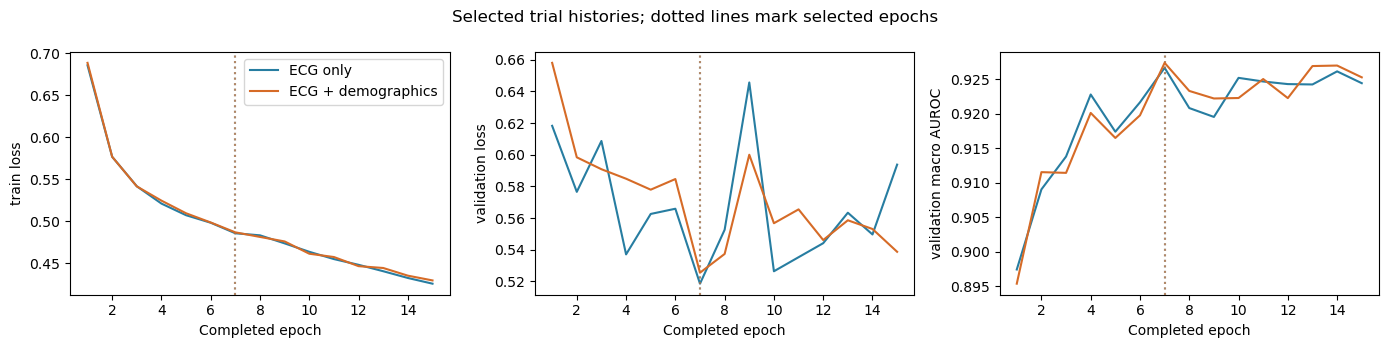

In [7]:
models, selected, hyperparameters = search_models(
    data, indices, parameters, OUTPUT, DEVICE, smoke=SMOKE, workers=WORKERS)
display(hyperparameters)
display(pd.DataFrame([{ "model": name, **result["config"],
                       "best_epoch": result["best_epoch"], "completed_epochs": result["completed_epochs"],
                       "completion_status": result["status"],
                       "validation_macro_AUROC": result["validation_macro_AUROC"]}
                      for name, result in selected.items()]))
plot_histories(selected, FIGURES)
plt.show()
if SMOKE:
    checks = smoke_checks(data, indices, parameters, models, selected, OUTPUT, DEVICE)
    display(pd.Series(checks, name="Smoke checks").to_frame())

## 4. Model evaluation
For each selected model, choose one threshold per class to maximize validation F1.
Use `probability >= threshold`; ties choose the largest optimal threshold. Freeze
both selected models and thresholds on disk **before** entering test evaluation.
Also report F1 at 0.5. ROC-AUC and AP use probabilities, never binary predictions.
If any class lacks positives or negatives, stop rather than silently changing the
five-class macro denominator.

,ECG only,ECG + demographics
validation-selected threshold,,
NORM,0.496884,0.371344
MI,0.605695,0.656427
STTC,0.683962,0.581703
CD,0.676561,0.836253
HYP,0.685544,0.824619


**Assessment: held-out test. Macro-AUPRC is macro average precision.**

,model,assessment,macro_AUROC,macro_F1,macro_AUPRC_AP,macro_F1_at_0_5
0,ECG only,held-out test,0.9218,0.7373,0.8087,0.7143
1,ECG + demographics,held-out test,0.9239,0.7406,0.8124,0.6945


,class_name,AUROC,average_precision,F1,precision,recall,threshold,model
0,NORM,0.9412,0.9195,0.8585,0.8120,0.9107,0.4969,ECG only
1,MI,0.9131,0.8017,0.7154,0.7023,0.7291,0.6057,ECG only
2,STTC,0.9321,0.8184,0.7622,0.7306,0.7965,0.6840,ECG only
3,CD,0.9171,0.8359,0.7453,0.7727,0.7198,0.6766,ECG only
4,HYP,0.9057,0.6678,0.6051,0.5480,0.6756,0.6855,ECG only
5,NORM,0.9461,0.9267,0.8608,0.8127,0.9148,0.3713,ECG + demographics
6,MI,0.9171,0.8068,0.7326,0.6657,0.8145,0.6564,ECG + demographics
7,STTC,0.9330,0.8213,0.7650,0.7495,0.7812,0.5817,ECG + demographics
8,CD,0.9145,0.8303,0.7337,0.8117,0.6694,0.8363,ECG + demographics
9,HYP,0.9088,0.6768,0.6108,0.6402,0.5840,0.8246,ECG + demographics


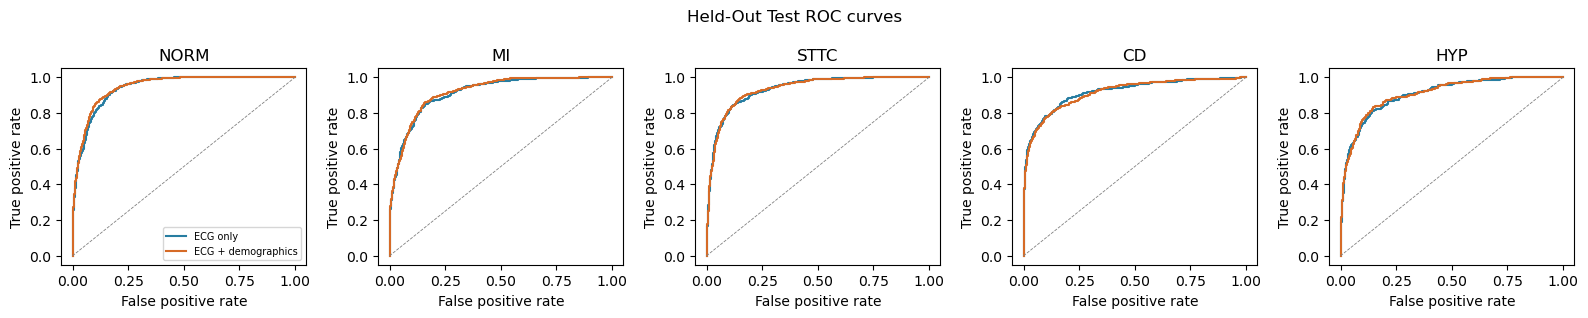

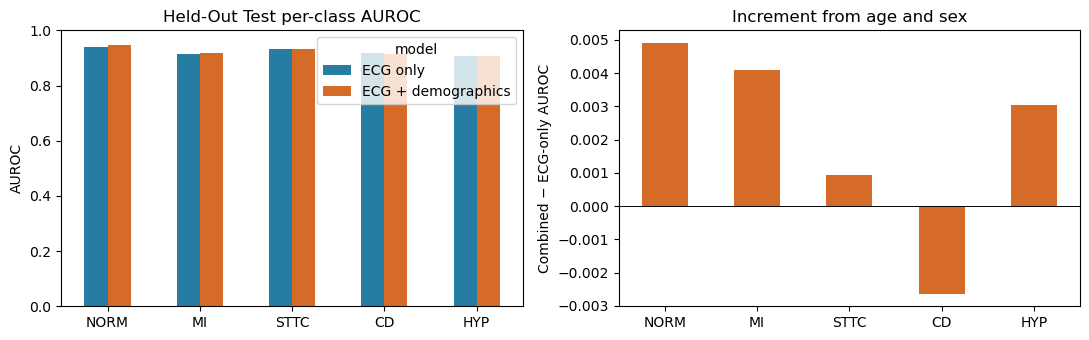

In [8]:
thresholds, validation_predictions = {}, {}
for name, model in models.items():
    loader = make_loader(ECGDataset(data, indices["validation"], parameters), BATCH_SIZE)
    y_validation, p_validation = predict(model, loader, DEVICE)
    thresholds[name] = select_thresholds(y_validation, p_validation)
    validation_predictions[name] = p_validation
frozen = {"cohort_hash": data["provenance"]["cohort_hash"],
          "model_fingerprints": {name: r["fingerprint"] for name, r in selected.items()},
          "thresholds": {name: t.tolist() for name, t in thresholds.items()},
          "threshold_source": "validation", "test_used_for_selection": False}
write_json(OUTPUT / "selection_frozen.json", frozen)
display(pd.DataFrame(thresholds, index=CLASSES).rename_axis("validation-selected threshold"))

partition = "validation" if SMOKE else "test"
assessment_label = "smoke validation (not final performance)" if SMOKE else "held-out test"
probabilities, overall_rows, per_class_tables = {}, [], []
evaluation_rows = indices[partition]
y_evaluation = data["y"][evaluation_rows]
for model_number, (name, model) in enumerate(models.items()):
    cache = OUTPUT / f"predictions_{partition}_{model_number}.npz"
    cache_signature = signature({"selection": frozen, "partition": partition})
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            assert str(saved["signature"].item()) == cache_signature
            assert np.array_equal(saved["recording_ids"], data["ids"][evaluation_rows])
            assert np.array_equal(saved["targets"], y_evaluation)
            p = saved["probabilities"]
    else:
        if SMOKE:
            p = validation_predictions[name]
        else:
            actual_y, p = predict(model, make_loader(ECGDataset(data, evaluation_rows, parameters), BATCH_SIZE), DEVICE)
            assert np.array_equal(actual_y, y_evaluation)
        np.savez_compressed(cache, probabilities=p, targets=y_evaluation,
                            recording_ids=data["ids"][evaluation_rows], signature=cache_signature)
    probabilities[name] = p
    overall, by_class = evaluate(y_evaluation, p, thresholds[name])
    overall_rows.append({"model": name, "assessment": assessment_label, **overall})
    by_class["model"] = name
    per_class_tables.append(by_class)
overall_performance = pd.DataFrame(overall_rows)
per_class_performance = pd.concat(per_class_tables, ignore_index=True)
overall_performance.to_csv(OUTPUT / f"{partition}_overall_performance.csv", index=False)
per_class_performance.to_csv(OUTPUT / f"{partition}_per_class_performance.csv", index=False)
display(Markdown(f"**Assessment: {assessment_label}. Macro-AUPRC is macro average precision.**"))
display(overall_performance.round(4))
display(per_class_performance.round(4))
plot_performance(y_evaluation, probabilities, per_class_performance, FIGURES, assessment_label)
plt.show()

## 5. Comparison of ECG-only and ECG + demographics models
Differences below are **combined minus ECG only**. A positive difference indicates
a larger metric for the combined model in this run. These are point estimates;
no statistical significance or causal benefit is implied.

In [9]:
metric_names = ["macro_AUROC", "macro_F1", "macro_AUPRC_AP", "macro_F1_at_0_5"]
metric_table = overall_performance.set_index("model")[metric_names]
increment = (metric_table.loc[MODEL_NAMES[1]] - metric_table.loc[MODEL_NAMES[0]]).rename("combined_minus_ECG_only")
display(increment.to_frame().round(4))
increment.to_csv(OUTPUT / f"{partition}_incremental_macro_metrics.csv")
auc_table = per_class_performance.pivot(index="class_name", columns="model", values="AUROC").reindex(CLASSES)
auc_difference = (auc_table[MODEL_NAMES[1]] - auc_table[MODEL_NAMES[0]]).rename("AUROC_change")
display(auc_difference.to_frame().round(4))
auc_difference.to_csv(OUTPUT / f"{partition}_incremental_class_AUROC.csv")

,combined_minus_ECG_only
macro_AUROC,0.0021
macro_F1,0.0033
macro_AUPRC_AP,0.0037
macro_F1_at_0_5,-0.0198


,AUROC_change
class_name,
NORM,0.0049
MI,0.0041
STTC,0.0009
CD,-0.0026
HYP,0.0030


## 6. Permutation feature importance
Use **validation data**, after model/threshold selection, for both models. For
one feature at a time, replace an entire lead's 1,000-point trace with another
recording's trace; age and sex are permuted individually for the combined model.
Targets and other features remain in place. Report the decrease in **macro-AUROC**
relative to the unpermuted validation baseline. The same donor permutations are
used for corresponding leads across the two models. Full mode uses 5 repeats;
smoke uses 2. Error bars are repeat SDs, not confidence intervals.

This is marginal, recording-level importance, not a patient-level bootstrap or a
causal effect. Correlated leads/demographics and physiologically unusual shuffled
combinations can affect the result. Negative values are retained. Do not use these
results to select features or revise models after observing test performance.

mean     std
model              feature                
ECG + demographics AVF      0.0200  0.0009
                   AVL      0.0046  0.0005
                   AVR      0.0034  0.0006
                   Age      0.0028  0.0005
                   I        0.0057  0.0005
                   II       0.0111  0.0010
                   III      0.0068  0.0010
                   Sex     -0.0001  0.0001
                   V1       0.0195  0.0009
                   V2       0.0179  0.0016
                   V3       0.0057  0.0005
                   V4       0.0030  0.0005
                   V5       0.0235  0.0011
                   V6       0.0133  0.0007
ECG only           AVF      0.0159  0.0015
                   AVL      0.0069  0.0008
                   AVR      0.0035  0.0006
                   I        0.0058  0.0007
                   II       0.0062  0.0004
                   III      0.0131  0.0012
                   V1       0.0191  0.0009
                   V2       0.0141  0.0018
                   V3       0.0045  0.0005
                   V4       0.0044  0.0008
                   V5       0.0290  0.0012
                   V6       0.0123  0.0005

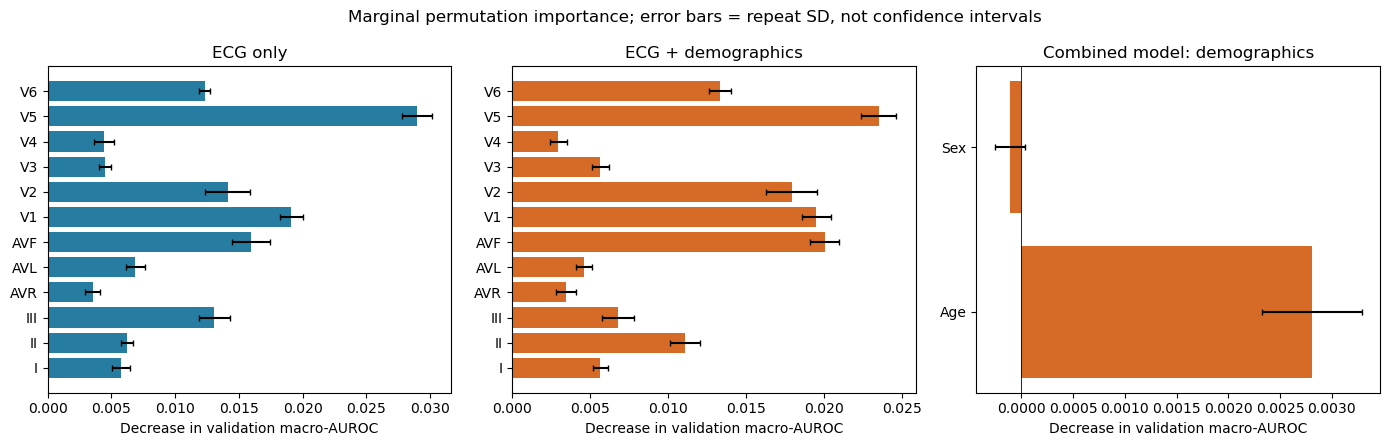

In [10]:
importance_tables = []
for name, model in models.items():
    cache = OUTPUT / ("importance_combined.csv" if name == MODEL_NAMES[1] else "importance_ecg.csv")
    meta_path = cache.with_suffix(".json")
    importance_signature = signature({"selection": frozen, "repeats": 2 if SMOKE else 5, "seed": SEED})
    if cache.exists() and meta_path.exists():
        assert read_json(meta_path)["signature"] == importance_signature
        importance = pd.read_csv(cache)
    else:
        importance = permutation_importance(model, data, indices["validation"], parameters,
            DEVICE, demographics=name == MODEL_NAMES[1], repeats=2 if SMOKE else 5, seed=SEED)
        importance.to_csv(cache, index=False)
        write_json(meta_path, {"signature": importance_signature, "partition": "validation"})
    importance["model"] = name
    importance_tables.append(importance)
importance_all = pd.concat(importance_tables, ignore_index=True)
importance_all.to_csv(OUTPUT / "permutation_importance_repeats.csv", index=False)
display(importance_all.groupby(["model", "feature"]).decrease_macro_AUROC.agg(["mean", "std"]).round(4))
plot_importance(importance_all, FIGURES)
plt.show()
if SMOKE:
    assert len(importance_all) == (12 + 14) * 2
    assert np.isfinite(importance_all.decrease_macro_AUROC).all()
    checks["permutation_importance_end_to_end"] = True

# Save completion records without displaying a separate summary section.
finalize_run(globals())